In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("E:/MSc files/Research/mpemba_functions/")
import mpemba

In [8]:
potential = mpemba.special_potentials.AsymmetricDoubleWellPotential(E_tilt=0.6, force_asymmetry=0.3, x_min=-6, x_max=6)

potential.F_left *= 0.8
potential.F_right *= 0.8

ensemble = mpemba.construct_simulated_ensemble(potential, [12,3,1], 10_000, expt_length=0.06)

100%|██████████| 5999/5999 [00:02<00:00, 2226.62it/s]


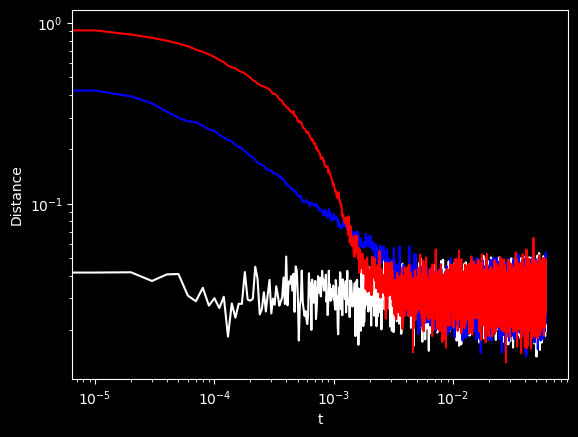

In [9]:
plt.close()
ensemble.plot_distances(colors=['r','b','w'])
plt.show()

In [15]:
ensemble.export_distances("bent_a0.8.csv")

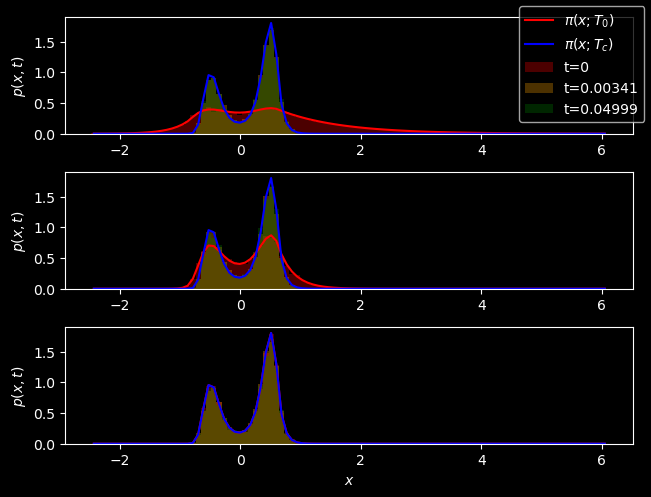

In [10]:
plt.close()
ensemble.plot_histograms()
plt.show()

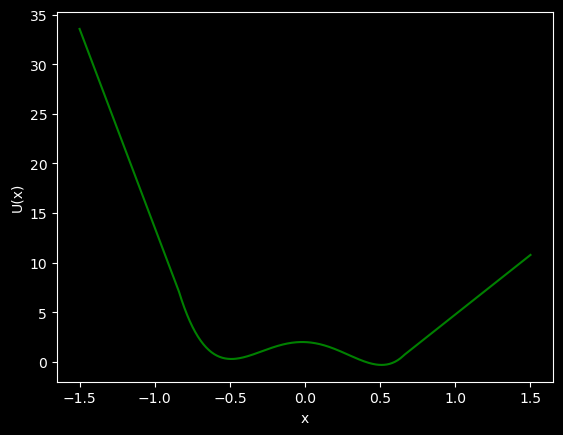

In [ ]:
x = np.linspace(-1.5,1.5,500)
plt.close()
ensemble.potential.plot_potential(plot_range=x)
plt.show()

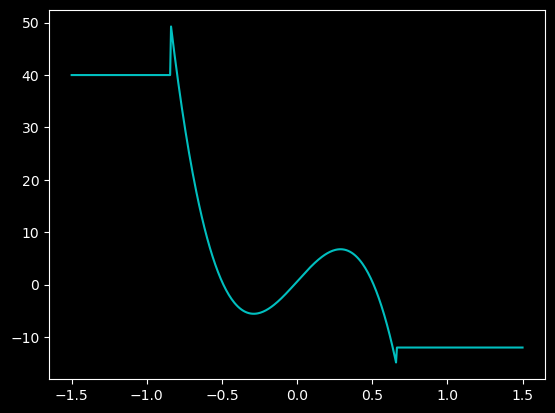

In [14]:
x = np.linspace(-1.5,1.5,500)
plt.close()
ensemble.potential.plot_force(plot_range=x)
plt.show()

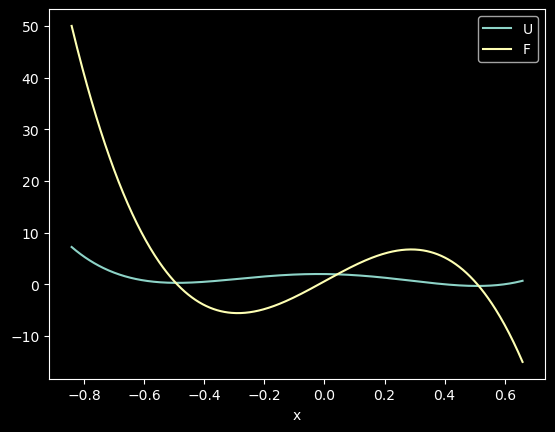

In [31]:
x = np.linspace(potential.x_l,potential.x_r,500)
x_left, x_right = np.linspace(-1.5, potential.x_l, 100), np.linspace(potential.x_r, 1.5, 100)
U_vals = potential.U(x)
F_vals = potential.F(x)
df = pd.DataFrame(np.array([U_vals, F_vals]).T, index=x, columns=['U','F'])
df.index.name='x'
plt.close()
df.plot()
df.to_csv("bent_potential_maindomain.csv")
U_left, U_right = potential.U(x_left), potential.U(x_right)
F_left, F_right = potential.F(x_left), potential.F(x_right)
df_left = pd.DataFrame(np.array([U_left, F_left]).T, index=x_left, columns=['U','F'])
df_right = pd.DataFrame(np.array([U_right, F_right]).T, index=x_right, columns=['U','F'])
# df_left.plot()
df_left.index.name='x'
df_right.index.name='x'
df_left.to_csv("bent_potential_left.csv")
df_right.to_csv("bent_potential_right.csv")
plt.show()